# Cardiovascular Disease (CVD) Risk Prediction – Kaggle Cardiovascular Disease dataset
UE24CS352A Machine Learning Mini-Project. Compares regularized logistic regression (Ridge, Lasso, Elastic net) with XGBoost (Extreme Gradient Boosting), evaluated with AUROC (Area Under the ROC Curve), following the reference paper.

**Setup:** `pip install numpy pandas scikit-learn xgboost matplotlib`, then place `cardio_train.csv` next to this notebook (or in `data/`) and run all cells (about 5–10 minutes).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, roc_curve
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
SEED = 0

## 1. Load the data

In [2]:
path = next(p for p in ["cardio_train.csv", "data/cardio_train.csv"] if os.path.exists(p))
df = pd.read_csv(path, sep=";")          # the Kaggle file is semicolon-separated
print(df.shape)
display(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Positive rate (cardio=1):", round(df.cardio.mean(), 3))
display(df.describe().T[["min", "max"]])

(70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


Missing values: 0
Positive rate (cardio=1): 0.5


,min,max
id,0.0,99999.0
age,10798.0,23713.0
gender,1.0,2.0
height,55.0,250.0
weight,10.0,200.0
ap_hi,-150.0,16020.0
ap_lo,-70.0,11000.0
cholesterol,1.0,3.0
gluc,1.0,3.0
smoke,0.0,1.0


## 2. Clean the data
The raw file contains impossible values (for example blood pressure of -150 or 16,020). We convert age from days to years, drop `id`, remove physiologically implausible rows, and add BMI (Body Mass Index).

In [3]:
df = df.drop(columns=["id"])
df["age"] = (df["age"] / 365.25).round(1)
n0 = len(df)
df = df[df.ap_hi.between(70, 250) & df.ap_lo.between(40, 150) & (df.ap_hi > df.ap_lo)
        & df.height.between(120, 220) & df.weight.between(30, 200)].copy()
df["bmi"] = df.weight / (df.height / 100) ** 2
print(f"Removed {n0 - len(df)} of {n0} rows -> {len(df)} patients, {df.shape[1] - 1} features")

y = df.pop("cardio").values
gender = df["gender"].values            # kept as a feature and used for the subgroup (fairness) check
X = df.values.astype(np.float32); features = list(df.columns)

Removed 1390 of 70000 rows -> 68610 patients, 12 features


## 3. Train/test split (80/20, stratified)

In [4]:
Xtr, Xte, ytr, yte, gtr, gte = train_test_split(X, y, gender, test_size=0.2, stratify=y, random_state=SEED)
print("train:", Xtr.shape, " test:", Xte.shape)
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)

train: (54888, 12)  test: (13722, 12)


## 4. Models and hyperparameter tuning
Grid search with 3-fold cross-validation, scoring on AUROC. Preprocessing (median imputation, scaling) is inside the pipeline to avoid data leakage.

In [5]:
def logreg(l1_ratio):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("clf", LogisticRegression(l1_ratio=l1_ratio, solver="saga", max_iter=300, tol=1e-3))])

models = {
    "LogReg (Ridge)":       GridSearchCV(logreg(0),   {"clf__C": [0.01, 0.1]}, scoring="roc_auc", cv=cv),
    "LogReg (Lasso)":       GridSearchCV(logreg(1),   {"clf__C": [0.01, 0.1]}, scoring="roc_auc", cv=cv),
    "LogReg (Elastic net)": GridSearchCV(logreg(0.5), {"clf__C": [0.01, 0.1]}, scoring="roc_auc", cv=cv),
    "XGBoost": GridSearchCV(XGBClassifier(n_estimators=300, tree_method="hist", eval_metric="auc", max_delta_step=1, n_jobs=-1),
                            {"max_depth": [4, 6], "learning_rate": [0.05, 0.1], "reg_lambda": [0.5, 1.0], "reg_alpha": [0.2, 0.5]},
                            scoring="roc_auc", cv=cv),
}
probs, rows = {}, []
for name, m in models.items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]; probs[name] = p
    rows.append({"Model": name, "CV AUROC": m.best_score_, "Test AUROC": roc_auc_score(yte, p),
                 "Test AUPRC": average_precision_score(yte, p), "Best params": m.best_params_})
    print(f"{name:22s} CV AUROC={m.best_score_:.4f}  Test AUROC={rows[-1]['Test AUROC']:.4f}  {m.best_params_}")

LogReg (Ridge)         CV AUROC=0.7904  Test AUROC=0.7946  {'clf__C': 0.1}


LogReg (Lasso)         CV AUROC=0.7904  Test AUROC=0.7947  {'clf__C': 0.01}


LogReg (Elastic net)   CV AUROC=0.7904  Test AUROC=0.7947  {'clf__C': 0.01}


XGBoost                CV AUROC=0.8004  Test AUROC=0.8036  {'learning_rate': 0.05, 'max_depth': 4, 'reg_alpha': 0.5, 'reg_lambda': 0.5}


## 5. Results table

In [6]:
results = pd.DataFrame(rows).set_index("Model")
display(results.style.format({"CV AUROC": "{:.3f}", "Test AUROC": "{:.3f}", "Test AUPRC": "{:.3f}"}))

,CV AUROC,Test AUROC,Test AUPRC,Best params
Model,,,,
LogReg (Ridge),0.790,0.795,0.776,{'clf__C': 0.1}
LogReg (Lasso),0.790,0.795,0.776,{'clf__C': 0.01}
LogReg (Elastic net),0.790,0.795,0.776,{'clf__C': 0.01}
XGBoost,0.800,0.804,0.783,"{'learning_rate': 0.05, 'max_depth': 4, 'reg_alpha': 0.5, 'reg_lambda': 0.5}"


## 6. ROC curves

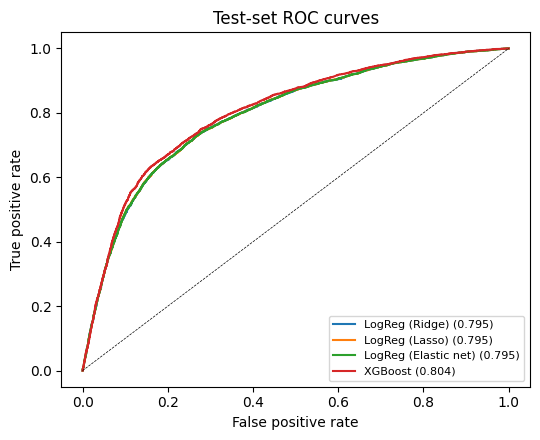

In [7]:
plt.figure(figsize=(5.5, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p); plt.plot(fpr, tpr, label=f"{name} ({results.loc[name, 'Test AUROC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Test-set ROC curves"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Best model: confusion matrix and metrics
Threshold = 3rd quartile of predicted probabilities (as in the reference paper).

In [8]:
best = results["Test AUROC"].idxmax(); pb = probs[best]
thr = np.quantile(pb, 0.75); pred = (pb >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print("Best model:", best, "| threshold:", round(float(thr), 4))
print(pd.DataFrame([[tn, fn], [fp, tp]], index=["Predicted 0", "Predicted 1"], columns=["Actual 0", "Actual 1"]))
print(f"Sensitivity={tp/(tp+fn):.4f}  Specificity={tn/(tn+fp):.4f}  Accuracy={(tp+tn)/len(yte):.4f}")

Best model: XGBoost | threshold: 0.7956
             Actual 0  Actual 1
Predicted 0      6406      3885
Predicted 1       528      2903
Sensitivity=0.4277  Specificity=0.9239  Accuracy=0.6784


## 8. Subgroup (gender) AUROC – fairness check

In [9]:
for g in np.unique(gte):
    mask = gte == g
    print(f"gender code {int(g)}: n={mask.sum()}, positive rate={yte[mask].mean():.3f}, AUROC={roc_auc_score(yte[mask], pb[mask]):.4f}")

gender code 1: n=8926, positive rate=0.492, AUROC=0.8021
gender code 2: n=4796, positive rate=0.500, AUROC=0.8065


## 9. Which features matter? (XGBoost feature importance)

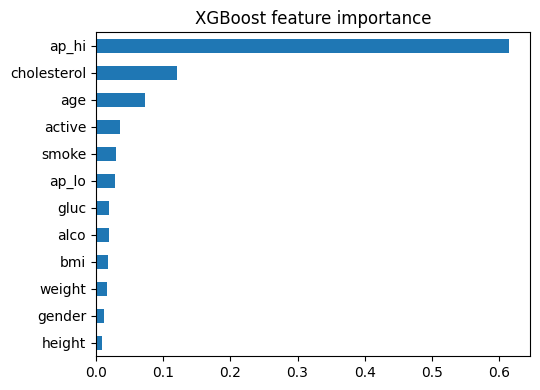

In [10]:
xgb = models["XGBoost"].best_estimator_
imp = pd.Series(xgb.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(5.5, 4), title="XGBoost feature importance"); plt.tight_layout(); plt.show()

## 10. Save results

In [11]:
os.makedirs("results", exist_ok=True)
results.drop(columns="Best params").round(4).to_csv("results/cardio_results.csv")
print("Saved results/cardio_results.csv")

Saved results/cardio_results.csv


## 11. Save the trained model (used by the live demo app)

In [12]:
import joblib
joblib.dump({"model": models["XGBoost"].best_estimator_, "features": features}, "xgb_cardio_model.joblib")
print("Saved xgb_cardio_model.joblib  (features:", features, ")")

Saved xgb_cardio_model.joblib  (features: ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi'] )
